# 🔬 Principal Component Analysis (PCA) from Scratch

**Goal:** Find the directions of maximum variance in the data and project onto a lower-dimensional space, discarding the directions of least variance.

---

## 1. Algorithm Intuition

PCA answers: *"Which directions in feature space capture the most information (variance)?"*

These directions are the **principal components** — orthogonal vectors arranged from most to least variance.

### Steps:
1. **Centre the data:** $X_{\text{centred}} = X - \bar{X}$ (subtract the column means).
2. **Compute the covariance matrix:** $\Sigma = \frac{1}{m-1} X_{\text{centred}}^T X_{\text{centred}}$, shape $(n, n)$.
3. **Eigendecomposition:** $\Sigma \mathbf{v} = \lambda \mathbf{v}$. The eigenvectors $\mathbf{v}$ are the principal components; eigenvalues $\lambda$ are the explained variances.
4. **Sort:** order eigenpairs by eigenvalue (descending).
5. **Project:** choose the top $d$ eigenvectors $V_d$ (shape $n \times d$) and compute $Z = X_{\text{centred}} V_d$.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $m$ | number of examples |
| $n$ | original number of features |
| $d$ | reduced number of components |
| $\Sigma$ | $n \times n$ covariance matrix |
| $\lambda_i$ | eigenvalue — variance explained by component $i$ |
| $\mathbf{v}_i$ | eigenvector — direction of component $i$ |
| $Z$ | projected (low-dimensional) data, shape $(m, d)$ |

---

## 2. Mathematical Note

We use **NumPy's `np.linalg.eigh`** (not `eig`) because the covariance matrix is symmetric and positive semi-definite. `eigh` is more numerically stable and always returns real eigenvalues.

**Explained variance ratio** for component $i$:
$$\text{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^{n} \lambda_j}$$


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic High-Dimensional Data

In [2]:
# Generate data with a clear low-dimensional structure:
# 3 classes embedded in 10-dimensional space, but truly separable in 2D.
rng = np.random.default_rng(7)

n_per_class = 100
n_original  = 10   # high-dimensional space

# Class centres in the first two dimensions only
def make_high_dim_data(n_per_class, n_original, seed=7):
    rng = np.random.default_rng(seed)
    centers_2d = np.array([[-4, 0], [4, 0], [0, 4]])

    X_list, y_list = [], []
    for label, c2d in enumerate(centers_2d):
        # First 2 dims: signal; remaining dims: pure noise
        signal = rng.normal(loc=c2d, scale=0.8, size=(n_per_class, 2))
        noise  = rng.normal(0, 0.5,             size=(n_per_class, n_original - 2))
        pts    = np.hstack([signal, noise])
        X_list.append(pts)
        y_list.append(np.full(n_per_class, label))

    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

X, y = make_high_dim_data(n_per_class, n_original)
print(f"X shape: {X.shape}  (m={X.shape[0]}, n={X.shape[1]})")

X shape: (300, 10)  (m=300, n=10)


## 5. Standardise Features

PCA is scale-sensitive. If one feature has variance 1000× another, it will dominate the principal components. Standardise using train-set statistics.

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

X_train, X_test, y_train, y_test = train_test_split(X, y)

# Fit scaler on training data ONLY
mu_train    = X_train.mean(axis=0)    # shape (n,)
sigma_train = X_train.std(axis=0)     # shape (n,)
sigma_train[sigma_train == 0] = 1

X_train_s = (X_train - mu_train) / sigma_train
X_test_s  = (X_test  - mu_train) / sigma_train

print(f"Train: {X_train_s.shape}, Test: {X_test_s.shape}")
print(f"Train mean ≈ {X_train_s.mean():.4f} (should be ~0)")

Train: (240, 10), Test: (60, 10)
Train mean ≈ 0.0000 (should be ~0)


## 6. PCA: Covariance → Eigendecomposition

In [4]:
def fit_pca(X_centred):
    """
    Fit PCA on a centred (and optionally scaled) feature matrix.

    Steps:
      1. Compute covariance matrix:  Sigma = X^T @ X / (m - 1)
      2. Eigendecompose Sigma using np.linalg.eigh (returns real eigenvalues
         because Sigma is symmetric positive semi-definite).
      3. Sort eigenpairs by descending eigenvalue.

    Parameters
    ----------
    X_centred : ndarray (m, n) — data with zero mean

    Returns
    -------
    eigenvalues  : ndarray (n,)    — sorted descending
    eigenvectors : ndarray (n, n)  — columns are principal components,
                                     sorted to match eigenvalues
    """
    m = X_centred.shape[0]

    # Covariance matrix: shape (n, n)
    # Division by (m - 1) for unbiased estimate
    Sigma = (X_centred.T @ X_centred) / (m - 1)

    print(f"Covariance matrix shape: {Sigma.shape}")

    # eigh returns eigenvalues in ascending order for symmetric matrices
    eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

    # Reverse to get descending order
    idx          = np.argsort(eigenvalues)[::-1]
    eigenvalues  = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]   # columns are eigenvectors

    return eigenvalues, eigenvectors

eigenvalues, eigenvectors = fit_pca(X_train_s)
print(f"\nTop 5 eigenvalues: {eigenvalues[:5].round(3)}")

Covariance matrix shape: (10, 10)

Top 5 eigenvalues: [1.451 1.204 1.138 1.093 1.017]


## 7. Explained Variance

In [5]:
# Only keep non-negative eigenvalues (numerical errors can produce tiny negatives)
eigenvalues_pos = np.maximum(eigenvalues, 0)

explained_var_ratio = eigenvalues_pos / eigenvalues_pos.sum()
cumulative_evr      = np.cumsum(explained_var_ratio)

print("Component | Eigenvalue | Explained Var | Cumulative")
print("-" * 55)
for i in range(n_original):
    print(f"  PC {i+1:2d}   |  {eigenvalues[i]:8.3f}  |    {explained_var_ratio[i]:.4f}     | {cumulative_evr[i]:.4f}")

Component | Eigenvalue | Explained Var | Cumulative
-------------------------------------------------------
  PC  1   |     1.451  |    0.1445     | 0.1445
  PC  2   |     1.204  |    0.1199     | 0.2644
  PC  3   |     1.138  |    0.1134     | 0.3777
  PC  4   |     1.093  |    0.1088     | 0.4866
  PC  5   |     1.017  |    0.1013     | 0.5878
  PC  6   |     0.981  |    0.0977     | 0.6856
  PC  7   |     0.895  |    0.0891     | 0.7747
  PC  8   |     0.784  |    0.0781     | 0.8528
  PC  9   |     0.764  |    0.0761     | 0.9289
  PC 10   |     0.714  |    0.0711     | 1.0000


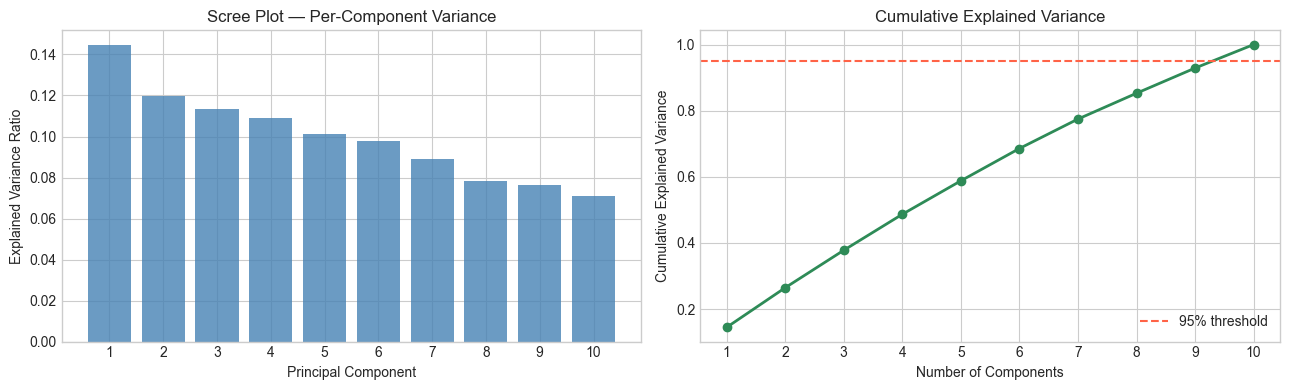

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

components = np.arange(1, n_original + 1)

axes[0].bar(components, explained_var_ratio, color='steelblue', alpha=0.8)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot — Per-Component Variance')
axes[0].set_xticks(components)

axes[1].plot(components, cumulative_evr, marker='o', color='seagreen', linewidth=2)
axes[1].axhline(0.95, color='tomato', linestyle='--', linewidth=1.5, label='95% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xticks(components)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Projection to d Dimensions

In [7]:
def project_pca(X, eigenvectors, d):
    """
    Project data onto the top d principal components.

    Z = X_centred @ V_d

    Parameters
    ----------
    X           : ndarray (m, n) — centred data
    eigenvectors: ndarray (n, n) — columns are PCs sorted by descending eigenvalue
    d           : int            — number of components to keep

    Returns
    -------
    Z : ndarray (m, d)
    """
    V_d = eigenvectors[:, :d]    # shape (n, d)
    Z   = X @ V_d                # shape (m, d)
    return Z

In [8]:
d = 2
Z_train = project_pca(X_train_s, eigenvectors, d)
Z_test  = project_pca(X_test_s,  eigenvectors, d)

print(f"Original shape  : {X_train_s.shape}")
print(f"Projected shape : {Z_train.shape}")

Original shape  : (240, 10)
Projected shape : (240, 2)


## 9. Visualise the 2D Projection

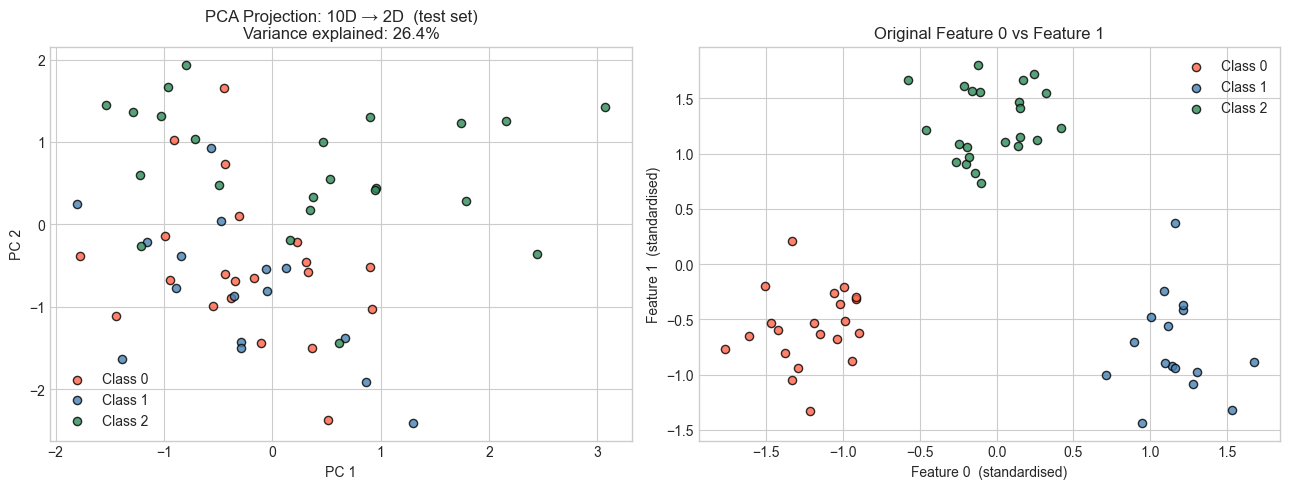

In [9]:
palette = ['tomato', 'steelblue', 'seagreen']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- PCA projection (test set) ---
for cls in range(3):
    mask = y_test.astype(int) == cls
    axes[0].scatter(Z_test[mask, 0], Z_test[mask, 1],
                    color=palette[cls], edgecolors='k', s=35,
                    label=f'Class {cls}', alpha=0.8)
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].set_title(f'PCA Projection: {n_original}D → 2D  (test set)\n'
                  f'Variance explained: {cumulative_evr[1]:.1%}')
axes[0].legend()

# --- Feature 0 vs Feature 1 in original space (for comparison) ---
for cls in range(3):
    mask = y_test.astype(int) == cls
    axes[1].scatter(X_test_s[mask, 0], X_test_s[mask, 1],
                    color=palette[cls], edgecolors='k', s=35,
                    label=f'Class {cls}', alpha=0.8)
axes[1].set_xlabel('Feature 0  (standardised)')
axes[1].set_ylabel('Feature 1  (standardised)')
axes[1].set_title('Original Feature 0 vs Feature 1')
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Reconstruction and Reconstruction Error

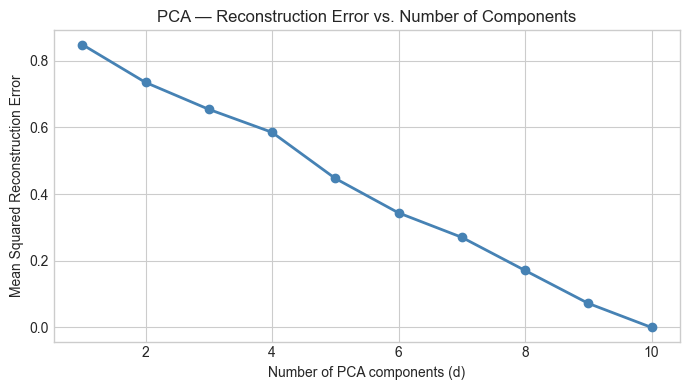

Reconstruction error at d=2: 0.7350
Reconstruction error at d=10: 0.0000  (should be ~0)


In [10]:
def reconstruct_pca(Z, eigenvectors, d):
    """
    Reconstruct the original-space data from the PCA projection.

    X_reconstructed = Z @ V_d^T    (shape: m x n)

    Note: reconstruction is an approximation; information from dropped
    components is permanently lost.
    """
    V_d = eigenvectors[:, :d]       # shape (n, d)
    return Z @ V_d.T                # shape (m, n)

# Reconstruction error for different d values
d_values = list(range(1, n_original + 1))
recon_errors = []

for dv in d_values:
    Z_dv = project_pca(X_test_s, eigenvectors, dv)
    X_dv_recon = reconstruct_pca(Z_dv, eigenvectors, dv)
    recon_error = np.mean((X_test_s - X_dv_recon) ** 2)
    recon_errors.append(recon_error)

plt.figure(figsize=(7, 4))
plt.plot(d_values, recon_errors, marker='o', color='steelblue', linewidth=2)
plt.xlabel('Number of PCA components (d)')
plt.ylabel('Mean Squared Reconstruction Error')
plt.title('PCA — Reconstruction Error vs. Number of Components')
plt.tight_layout()
plt.show()

print(f"Reconstruction error at d=2: {recon_errors[1]:.4f}")
print(f"Reconstruction error at d={n_original}: {recon_errors[-1]:.4f}  (should be ~0)")

## 11. Principal Component Loadings

The loadings (entries of the eigenvectors) tell us which original features contribute most to each PC.

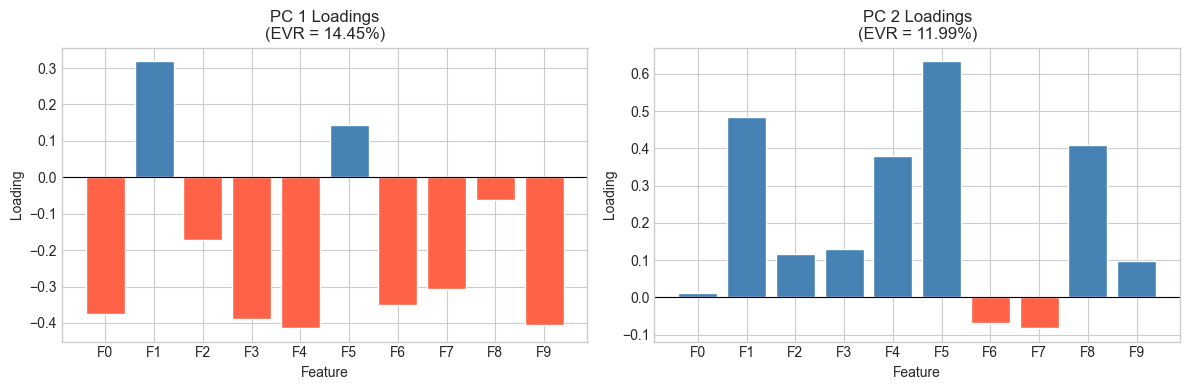

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

feature_labels = [f'F{i}' for i in range(n_original)]

for pc_idx, ax in enumerate(axes):
    loadings = eigenvectors[:, pc_idx]   # shape (n,)
    colors   = ['steelblue' if v >= 0 else 'tomato' for v in loadings]
    ax.bar(feature_labels, loadings, color=colors, edgecolor='white')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'PC {pc_idx + 1} Loadings\n'
                 f'(EVR = {explained_var_ratio[pc_idx]:.2%})')
    ax.set_xlabel('Feature')
    ax.set_ylabel('Loading')

plt.tight_layout()
plt.show()

## 12. Observations and Limitations

### What we observed
- The top 2 PCs recover the 2D signal and make the three classes clearly separable.
- The scree plot shows a sharp drop after PC 2 — the remaining components are mostly noise.
- Reconstruction error approaches zero as $d \to n$.
- Loadings for PC 1 and PC 2 are dominated by features 0 and 1 (the signal dimensions).

### Limitations
| Limitation | Description |
|------------|-------------|
| **Linear only** | PCA finds linear projections; nonlinear structure requires Kernel PCA or autoencoders. |
| **Variance ≠ Information** | High variance is not always the most discriminative direction; LDA maximises class separability instead. |
| **Scale sensitivity** | Requires standardisation; otherwise high-variance features dominate. |
| **Interpretability** | PCs are linear combinations of all features — hard to interpret directly. |
| **Eigendecomposition cost** | $O(n^3)$ to compute; use SVD for $m \ll n$ (tall-and-thin matrices). |
